# Анализ и прогнозирование цен подержанных автомобилей

**Команда № 180**

| Участник | Группа |
|---|---|
| Павчун Дмитрий | 8 |
| Алимова Яна | 11 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from scipy import stats
from scipy.stats import shapiro
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest

## 1. Описание данных

In [2]:
df = pd.read_excel('Автомобили.xlsx')
print('Размер датасета:', df.shape)
df.head()

Размер датасета: (700, 13)


,Производитель,Модель,"Возраст автомобиля, лет","Пробег, миль",Состояние,Тип кузова,Тип топлива,Электромобиль,Коробка передач,Привод,Количество цилиндров,Цвет,"Цена, USD"
0,Ford,super duty f-250 srw,5,118000,Отличное,Грузовик,Дизель,Нет,Автоматическая,Полный,8.0,Черный,43900
1,Chevrolet,silverado 1500,4,133329,Хорошее,Грузовик,Бензин,Нет,Автоматическая,Полный,8.0,Серебристый,26990
2,Ford,thunderbird,18,33970,Отличное,Кабриолет,Бензин,Нет,Автоматическая,Задний,8.0,Красный,18990
3,Ford,f150 platinum 4x4,9,175489,Как новый,Пикап,Бензин,Нет,Автоматическая,Полный,NaN,Черный,14777
4,Tesla,model 3,3,18900,Отличное,Седан,Электричество,Да,Другое,Задний,0.0,Белый,42200


- **Тема датасета:** объявления о продаже подержанных автомобилей в США: марка и модель, возраст, пробег, техническое состояние, характеристики кузова и двигателя, цвет и цена.
- **Наблюдение:** один автомобиль, выставленный на продажу.
- **Источник:** Used Cars Dataset с платформы Kaggle (объявления сайта Craigslist, 426 880 строк). Из него отобрано 700 автомобилей разных марок, типов кузова, ценовых категорий и видов топлива, включая электромобили и гибриды. Названия признаков и категорий переведены на русский язык, марки, модели и числа оставлены как в исходных данных.
- **Размер:** 700 наблюдений и 13 признаков.
- **Целевой признак:** `Цена, USD`. Он количественный, поэтому для прогноза используется линейная регрессия.

## 2. Описание признаков

In [3]:
df.dtypes

Производитель               object
Модель                      object
Возраст автомобиля, лет      int64
Пробег, миль                 int64
Состояние                   object
Тип кузова                  object
Тип топлива                 object
Электромобиль               object
Коробка передач             object
Привод                      object
Количество цилиндров       float64
Цвет                        object
Цена, USD                    int64
dtype: object

| № | Признак | Описание | Формат | Тип данных |
|---|---|---|---|---|
| 1 | Производитель | Марка автомобиля (Ford, Toyota, Tesla и т.д.) | object | Категориальный номинальный |
| 2 | Модель | Модель автомобиля | object | Категориальный номинальный |
| 3 | Возраст автомобиля, лет | Сколько лет прошло с года выпуска | int64 | Количественный дискретный |
| 4 | Пробег, миль | Пробег по одометру | int64 | Количественный непрерывный |
| 5 | Состояние | Техническое состояние: Аварийное < Удовлетворительное < Хорошее < Отличное < Как новый < Новый | object | Категориальный порядковый |
| 6 | Тип кузова | Седан, внедорожник, пикап и т.д. | object | Категориальный номинальный |
| 7 | Тип топлива | Бензин, дизель, гибрид, электричество, другое | object | Категориальный номинальный |
| 8 | Электромобиль | Является ли автомобиль электромобилем (Да / Нет) | object | Категориальный бинарный |
| 9 | Коробка передач | Автоматическая, механическая, другое | object | Категориальный номинальный |
| 10 | Привод | Передний, задний, полный | object | Категориальный номинальный |
| 11 | Количество цилиндров | Число цилиндров двигателя (0 у электромобилей) | float64 | Количественный дискретный |
| 12 | Цвет | Цвет кузова | object | Категориальный номинальный |
| 13 | Цена, USD | Цена автомобиля в долларах (целевой признак) | int64 | Количественный непрерывный |

**Комментарии к классификации:**

- `Количество цилиндров` по смыслу целое число, но имеет формат `float64`. В столбце есть пропуски (`NaN`), а `NaN` в pandas относится к типу float, поэтому весь столбец хранится как `float64`. По смыслу признак количественный дискретный.
- `Состояние` - единственный порядковый признак: его категории можно упорядочить от худшего к лучшему. У остальных категориальных признаков порядка нет (нельзя сказать, что белый цвет «больше» синего).
- `Электромобиль` - бинарный признак: ровно два значения, Да и Нет.
- `Пробег` и `Цена` отнесены к непрерывным: это измеряемые величины, которые могут принимать любое значение на интервале, целые числа в данных появились из-за округления.

## 3. Пропуски и дубликаты

In [4]:
df.isna().sum()

Производитель               0
Модель                      0
Возраст автомобиля, лет     0
Пробег, миль                0
Состояние                   0
Тип кузова                  0
Тип топлива                 0
Электромобиль               0
Коробка передач             0
Привод                     40
Количество цилиндров       27
Цвет                       18
Цена, USD                   0
dtype: int64

In [5]:
(df.isna().mean() * 100).round(2)

Производитель              0.00
Модель                     0.00
Возраст автомобиля, лет    0.00
Пробег, миль               0.00
Состояние                  0.00
Тип кузова                 0.00
Тип топлива                0.00
Электромобиль              0.00
Коробка передач            0.00
Привод                     5.71
Количество цилиндров       3.86
Цвет                       2.57
Цена, USD                  0.00
dtype: float64

In [6]:
print('Полных дубликатов:', df.duplicated().sum())

Полных дубликатов: 35


In [7]:
df_clean = df.drop_duplicates().copy()

print('Мода признака Привод:', df_clean['Привод'].mode()[0])
print('Мода признака Цвет:', df_clean['Цвет'].mode()[0])
print('Количество цилиндров: среднее =', round(df_clean['Количество цилиндров'].mean(), 2),
      ', медиана =', df_clean['Количество цилиндров'].median(),
      ', мода =', df_clean['Количество цилиндров'].mode()[0])

Мода признака Привод: Полный
Мода признака Цвет: Белый
Количество цилиндров: среднее = 5.59 , медиана = 6.0 , мода = 8.0


In [8]:
df_clean['Привод'] = df_clean['Привод'].fillna(df_clean['Привод'].mode()[0])
df_clean['Цвет'] = df_clean['Цвет'].fillna(df_clean['Цвет'].mode()[0])
df_clean['Количество цилиндров'] = df_clean['Количество цилиндров'].fillna(df_clean['Количество цилиндров'].median())
df_clean['Количество цилиндров'] = df_clean['Количество цилиндров'].astype('int64')

print('Пропусков после заполнения:', df_clean.isna().sum().sum())
print('Размер df_clean:', df_clean.shape)

Пропусков после заполнения: 0
Размер df_clean: (665, 13)


**Выводы:**

- Пропуски есть в трёх признаках: `Привод` - 40 (5.71%), `Количество цилиндров` - 27 (3.86%), `Цвет` - 18 (2.57%). Доля пропусков везде меньше 6%, поэтому строки не удаляем, а заполняем пропуски.
- Найдено 35 полных дубликатов строк, они удалены. Дубликаты удаляем до заполнения пропусков, чтобы повторяющиеся строки не влияли на моду и медиану.
- `Привод` и `Цвет` - категориальные признаки, поэтому пропуски заполнены модой: «Полный» и «Белый». Для текстовых категорий можно посчитать только частоту, среднее и медиана для них не определены.
- `Количество цилиндров` - количественный дискретный признак, пропуски заполнены медианой (6). Среднее (5.59) дробное, а дробного числа цилиндров не бывает, к тому же среднее неустойчиво к крайним значениям (0 у электромобилей). Мода (8) показывает только самое частое значение и смещена в сторону мощных пикапов. Медиана устойчива к выбросам и даёт реальное значение.
- После заполнения пропусков `Количество цилиндров` приведён к формату `int64`, так как причина формата `float64` (наличие `NaN`) устранена.
- Итог: в датафрейме **df_clean** 665 строк и 13 признаков, пропусков и дубликатов нет. Дальше работаем с ним.

## 4. Выбросы

### 4.1. Ящики с усами

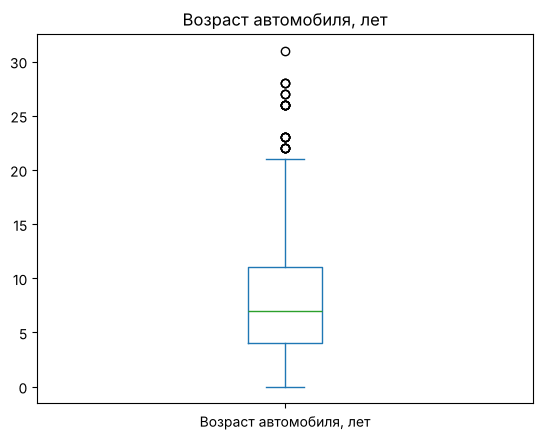

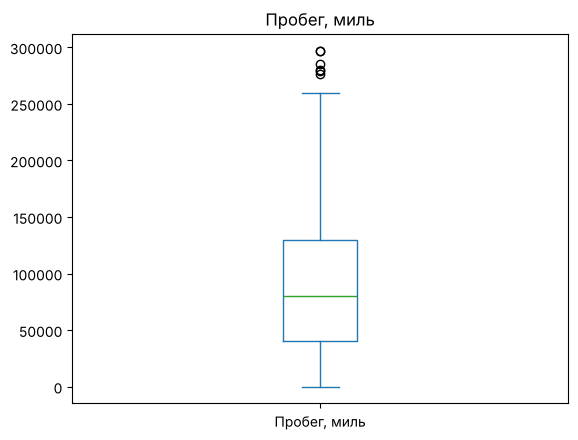

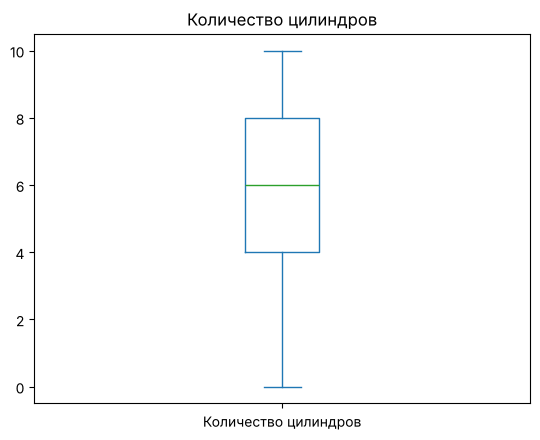

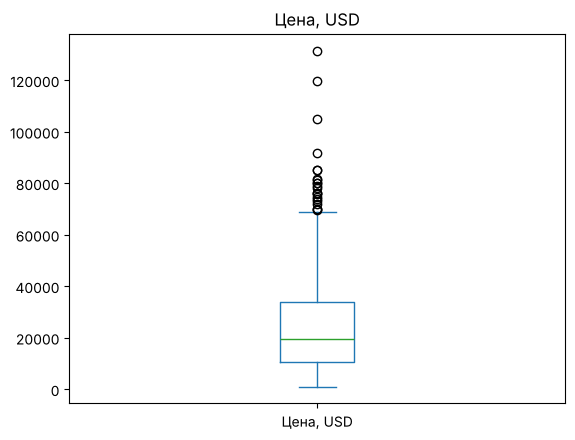

In [9]:
num_cols = ['Возраст автомобиля, лет', 'Пробег, миль', 'Количество цилиндров', 'Цена, USD']

for col in num_cols:
    df_clean[col].plot(kind='box', title=col)
    plt.show()

In [10]:
for col in num_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    print(col, ': граница правого уса =', q3 + 1.5 * iqr,
          ', точек выше уса =', (df_clean[col] > q3 + 1.5 * iqr).sum(),
          ', точек ниже уса =', (df_clean[col] < q1 - 1.5 * iqr).sum())

Возраст автомобиля, лет : граница правого уса = 21.5 , точек выше уса = 26 , точек ниже уса = 0
Пробег, миль : граница правого уса = 263781.0 , точек выше уса = 6 , точек ниже уса = 0
Количество цилиндров : граница правого уса = 14.0 , точек выше уса = 0 , точек ниже уса = 0
Цена, USD : граница правого уса = 69237.5 , точек выше уса = 22 , точек ниже уса = 0


**Выводы:**

- `Цена, USD`: 22 точки выше правого уса (дороже 69 237.5 USD), максимум 131 500. Распределение заметно скошено вправо: верхний ус и хвост из точек намного длиннее нижнего.
- `Пробег, миль`: 6 точек выше уса, это автомобили с пробегом больше 263 781 мили.
- `Возраст автомобиля, лет`: 26 точек выше уса, это машины старше 21.5 года. Ящик занимает диапазон от 4 до 11 лет, то есть у трёх четвертей автомобилей возраст не больше 11 лет.
- `Количество цилиндров`: выбросов нет, все значения от 0 (электромобили) до 10 лежат внутри усов.
- Ниже нижнего уса нет ни одной точки ни у одного признака: все выбросы находятся сверху.

### 4.2. Метод N стандартных отклонений

In [11]:
col = df_clean['Цена, USD']
avg = col.mean()
std = col.std()
left = avg - 3 * std
right = avg + 3 * std

df_no_std = df_clean[col.between(left, right)].copy()

print('Среднее:', round(avg, 2), ', стандартное отклонение:', round(std, 2))
print('Границы:', round(left, 2), 'и', round(right, 2))
print('Удалено строк при N = 3:', len(df_clean) - len(df_no_std))
print('Удалено строк, если взять N = 2:', len(df_clean) - len(df_clean[col.between(avg - 2 * std, avg + 2 * std)]))
print('Удалённые цены:', df_clean[col > right]['Цена, USD'].min(), '-', df_clean[col > right]['Цена, USD'].max())
print('Размер df_no_std:', df_no_std.shape)

Среднее: 24543.06 , стандартное отклонение: 18784.83
Границы: -31811.43 и 80897.55
Удалено строк при N = 3: 8
Удалено строк, если взять N = 2: 30
Удалённые цены: 81250 - 131500
Размер df_no_std: (657, 13)


**Выводы:**

- По разъяснению ассистента, выбросы отслеживаются прежде всего по предикторам, но отдельно проверить целевую переменную тоже полезно. Поэтому методом N стандартных отклонений чистим целевую переменную `Цена, USD`, а предиктор `Пробег, миль` чистим методом 1.5 * IQR в п. 4.3.
- Выбрано **N = 3**. При N = 2 удалилось бы 30 строк (4.5% выборки), среди них обычные дорогие, но реальные автомобили, и мы потеряли бы информацию для регрессии. При N = 3 отсекаются только самые нетипичные цены.
- Среднее 24 543.06, стандартное отклонение 18 784.83. Границы: от -31 811.43 до 80 897.55 USD.
- Удалено 8 автомобилей дороже 80 897.55 USD (от 81 250 до 131 500 USD).
- Итог: в датафрейме **df_no_std** 657 строк. Метод IQR применяем уже к нему.

### 4.3. Метод 1.5 * IQR

In [12]:
col = df_no_std['Пробег, миль']
q1 = col.quantile(0.25)
q3 = col.quantile(0.75)
iqr = q3 - q1
left = q1 - 1.5 * iqr
right = q3 + 1.5 * iqr

df_final = df_no_std[col.between(left, right)].copy()

print('Q1 =', q1, ', Q3 =', q3, ', IQR =', iqr)
print('Границы:', left, 'и', right)
print('Удалено строк:', len(df_no_std) - len(df_final))
print('Максимальный пробег до чистки:', col.max())
print('Размер df_final:', df_final.shape)

Q1 = 42616.0 , Q3 = 129960.0 , IQR = 87344.0
Границы: -88400.0 и 260976.0
Удалено строк: 6
Максимальный пробег до чистки: 297062
Размер df_final: (651, 13)


**Выводы:**

- Чистим предиктор `Пробег, миль`, данные берём из `df_no_std`.
- Q1 = 42 616, Q3 = 129 960, IQR = 87 344 мили. Границы: от -88 400 до 260 976 миль.
- Удалено 6 автомобилей с пробегом больше 260 976 миль (максимум был 297 062 мили). Такой пробег сильно выделяется на фоне остальных автомобилей.
- Итог: в датафрейме **df_final** 651 строка. Цепочка: 700 строк в исходных данных, 665 после удаления дубликатов, 657 после метода 3 стандартных отклонений, 651 после метода IQR. Дальше во всех разделах работаем с **df_final**.

**Почему левая граница в обоих методах отрицательная:**

- Оба признака скошены вправо: основная масса значений находится ближе к нулю, а длинный правый хвост сильно увеличивает разброс.
- В методе N * std стандартное отклонение цены (18 785) велико относительно среднего (24 543), поэтому `avg - 3 * std` уходит ниже нуля. В методе IQR межквартильный размах (87 344) больше Q1 (42 616), поэтому `q1 - 1.5 * iqr` тоже отрицательная.
- Цена и пробег не бывают отрицательными, поэтому левая граница ничего не отсекает и фактически работает только правая.

## 5. Визуализация

### 5.1. Гистограммы количественных признаков

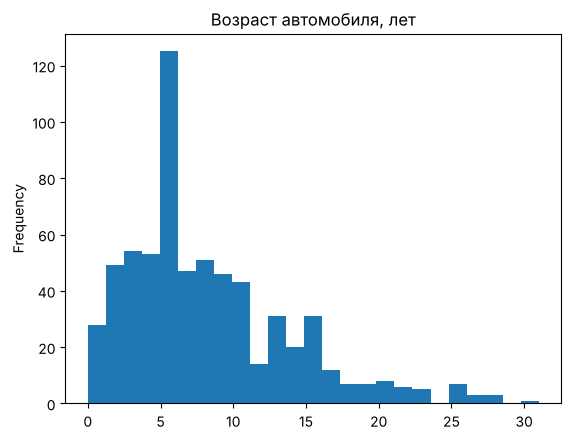

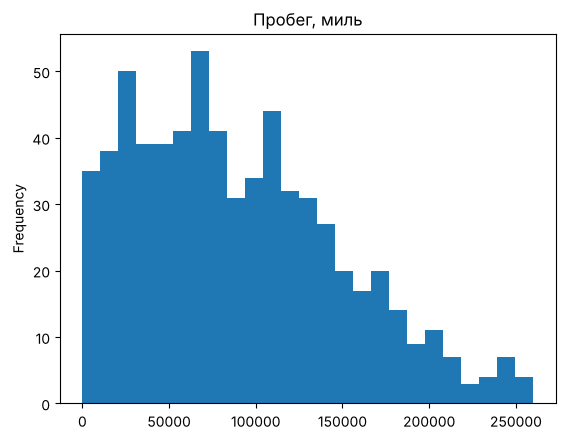

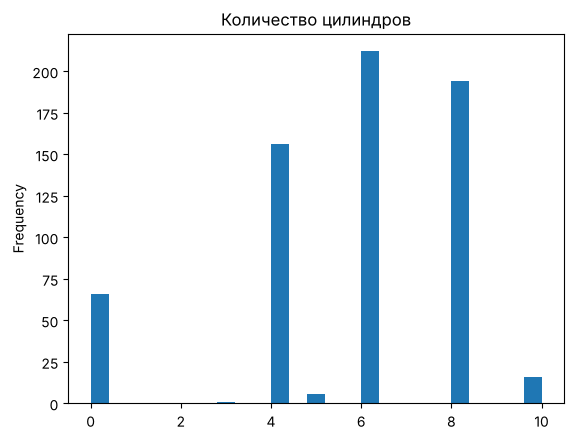

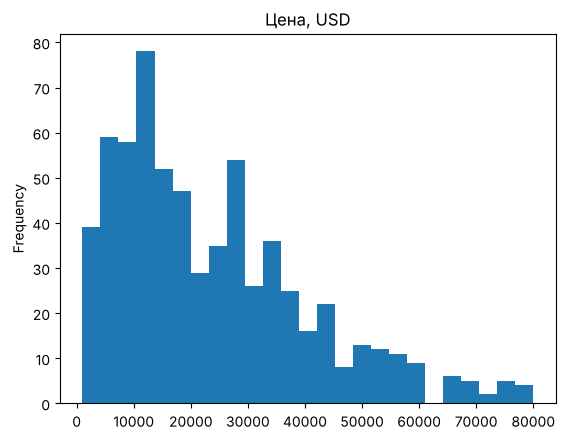

In [13]:
for col in num_cols:
    df_final[col].plot(kind='hist', bins=25, title=col)
    plt.show()

In [14]:
df_final[num_cols].skew().round(2)

Возраст автомобиля, лет    1.21
Пробег, миль               0.60
Количество цилиндров      -0.84
Цена, USD                  1.02
dtype: float64

**Выводы по распределению количественных признаков:**

- **Цена, USD.** Распределение скошено вправо, коэффициент асимметрии 1.02. Самые высокие столбцы приходятся на цены примерно до 20 тыс. USD, дальше частота постепенно снижается, а справа тянется хвост дорогих автомобилей до 80 тыс. Среднее (23 767) больше медианы (19 500): длинный правый хвост тянет среднее вверх.
- **Пробег, миль.** Умеренная правосторонняя асимметрия, 0.60. Распределение ближе к симметричному, чем у цены: чаще всего встречается пробег от 40 до 130 тыс. миль, есть и группа почти новых машин с пробегом около нуля.
- **Возраст автомобиля, лет.** Самая сильная скошенность вправо среди количественных признаков, 1.21. Больше половины машин не старше 7 лет, после 15 лет частота резко падает, отдельные автомобили доходят до 31 года.
- **Количество цилиндров.** Признак дискретный, поэтому гистограмма состоит из отдельных столбцов: 4 цилиндра (156 машин), 6 (212) и 8 (194). Отдельно стоит столбец 0 - это 66 электромобилей. Значения 3, 5 и 10 встречаются редко. Асимметрия отрицательная (-0.84): левый хвост создают электромобили с нулём цилиндров.
- Общий вывод: цена, пробег и возраст скошены вправо, что типично для рыночных данных: дешёвых и массовых автомобилей больше, чем дорогих и редких.

### 5.2. Столбчатые диаграммы категориальных признаков

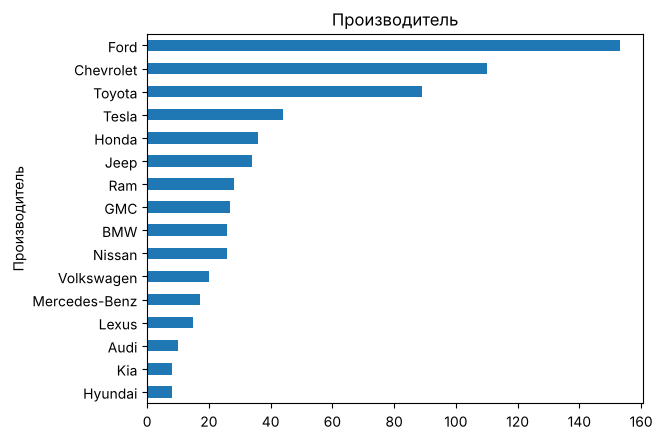

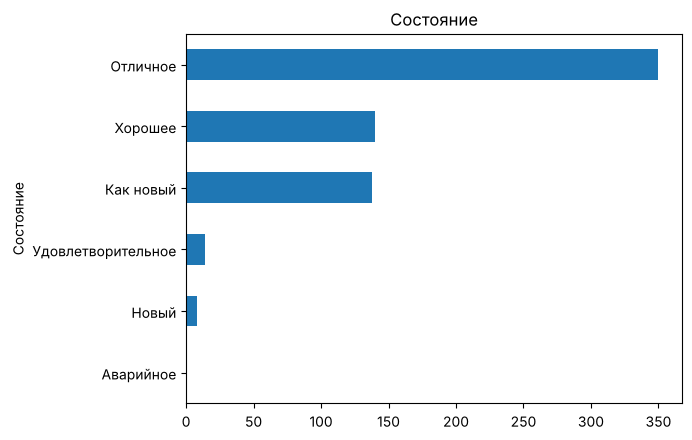

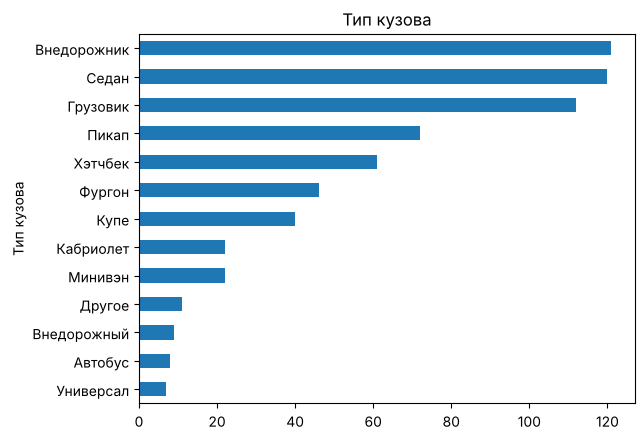

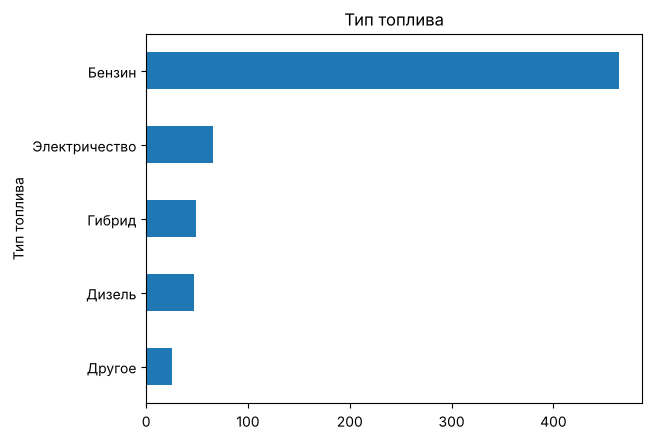

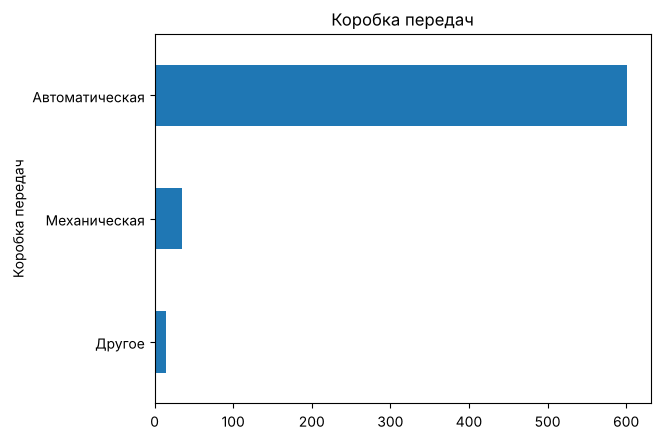

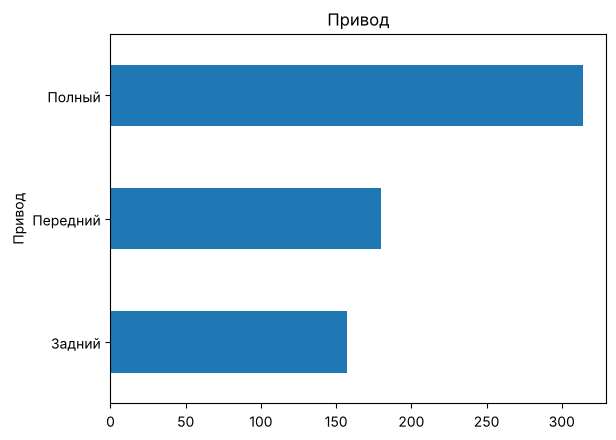

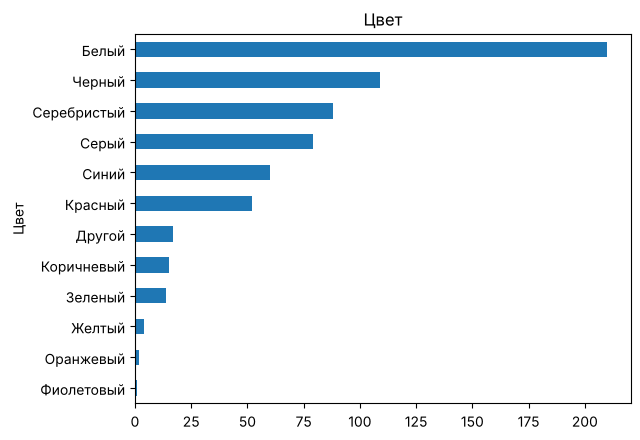

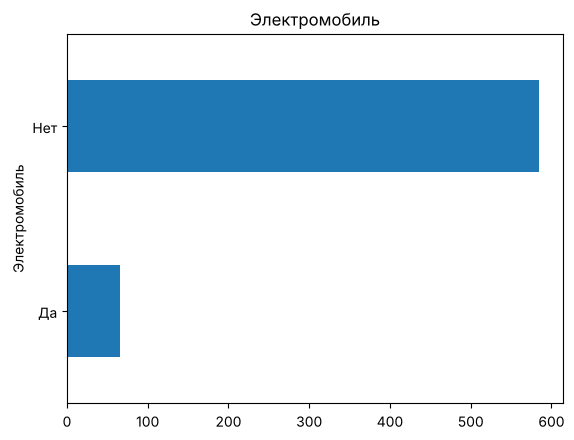

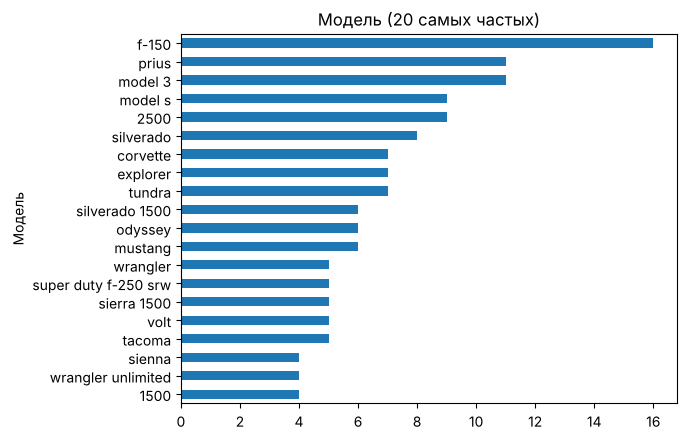

In [15]:
cat_cols = ['Производитель', 'Состояние', 'Тип кузова', 'Тип топлива',
            'Коробка передач', 'Привод', 'Цвет', 'Электромобиль']

for col in cat_cols:
    df_final[col].value_counts().sort_values().plot(kind='barh', title=col)
    plt.show()

df_final['Модель'].value_counts().head(20).sort_values().plot(kind='barh', title='Модель (20 самых частых)')
plt.show()

In [16]:
for col in cat_cols:
    print(df_final[col].value_counts(), '\n')

Производитель
Ford             153
Chevrolet        110
Toyota            89
Tesla             44
Honda             36
Jeep              34
Ram               28
GMC               27
BMW               26
Nissan            26
Volkswagen        20
Mercedes-Benz     17
Lexus             15
Audi              10
Kia                8
Hyundai            8
Name: count, dtype: int64 

Состояние
Отличное              350
Хорошее               140
Как новый             138
Удовлетворительное     14
Новый                   8
Аварийное               1
Name: count, dtype: int64 

Тип кузова
Внедорожник    121
Седан          120
Грузовик       112
Пикап           72
Хэтчбек         61
Фургон          46
Купе            40
Минивэн         22
Кабриолет       22
Другое          11
Внедорожный      9
Автобус          8
Универсал        7
Name: count, dtype: int64 

Тип топлива
Бензин           464
Электричество     66
Гибрид            49
Дизель            47
Другое            25
Name: count, dtype: int64

**Выводы по распределению категориальных признаков:**

- **Производитель.** 16 марок, больше всего Ford (153 машины, 23.5%), затем Chevrolet (110) и Toyota (89). Выборка смещена в сторону американских брендов, что ожидаемо для рынка США. Отдельно выделяется Tesla (44 машины): на неё приходится 43 из 66 электромобилей.
- **Модель.** 444 разных значения, самая частая модель f-150 встречается всего 16 раз. Диаграмма для всех 444 моделей была бы нечитаемой, поэтому показаны 20 самых частых.
- **Состояние.** Преобладает «Отличное» (350 машин, 53.8%), затем «Хорошее» (140) и «Как новый» (138). Крайние категории представлены слабо: «Удовлетворительное» - 14, «Новый» - 8, «Аварийное» - 1 автомобиль. Выводы по этим трём категориям ненадёжны из-за малого числа наблюдений.
- **Тип кузова.** 13 категорий, лидеры почти вровень: внедорожник (121), седан (120) и грузовик (112). Ни один тип кузова не доминирует.
- **Тип топлива.** Сильный перекос: бензин у 464 машин (71.3%). Электричество (66), гибрид (49) и дизель (47) представлены примерно одинаково, «Другое» - 25.
- **Коробка передач.** 92.3% автоматов (601 машина), механика (35) и «Другое» (15) встречаются редко, что типично для американского рынка.
- **Привод.** Полный 314 (48.2%), передний 180, задний 157. Это самый сбалансированный из признаков с тремя категориями.
- **Цвет.** 12 цветов, лидирует белый (210, 32.3%), затем чёрный (109) и серебристый (88). Яркие цвета (жёлтый, оранжевый, фиолетовый) единичны.
- **Электромобиль.** 66 электромобилей из 651 (10.1%). Группа небольшая, но её хватает для сравнения с остальными машинами.

### 5.3. Скрипичные графики: связь цены с признаками

Скрипичный график показывает распределение количественного признака внутри групп, поэтому количественные предикторы сначала разбиваем на группы. Для возраста и пробега используем квартили: до Q1 - «низкий», от Q1 до Q3 - «средний», выше Q3 - «высокий». Количество цилиндров делим на группы по числу цилиндров. Группы создаём в отдельной копии данных `df_viol`, чтобы не менять `df_final`. Параметр `cut=0` обрезает скрипку по минимальной и максимальной цене в группе, иначе сглаженный контур уходит в отрицательные цены, которых не бывает.

In [17]:
df_viol = df_final.copy()

age = df_viol['Возраст автомобиля, лет']
df_viol['Группа возраста'] = np.where(age <= age.quantile(0.25), 'низкий',
                              np.where(age <= age.quantile(0.75), 'средний', 'высокий'))

mileage = df_viol['Пробег, миль']
df_viol['Группа пробега'] = np.where(mileage <= mileage.quantile(0.25), 'низкий',
                             np.where(mileage <= mileage.quantile(0.75), 'средний', 'высокий'))

cyl = df_viol['Количество цилиндров']
df_viol['Группа цилиндров'] = np.where(cyl == 0, '0',
                               np.where(cyl <= 4, '3-4',
                               np.where(cyl <= 6, '5-6', '8-10')))

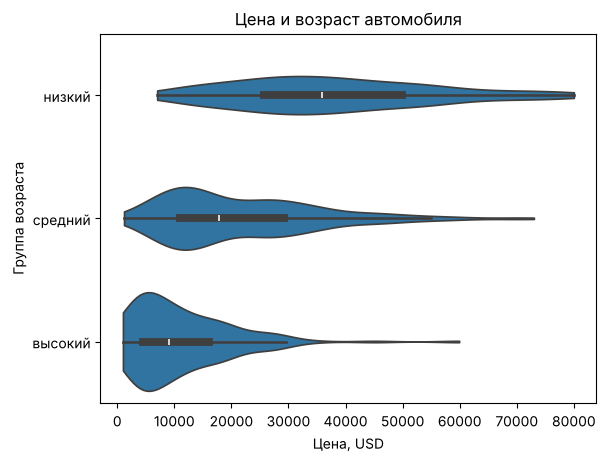

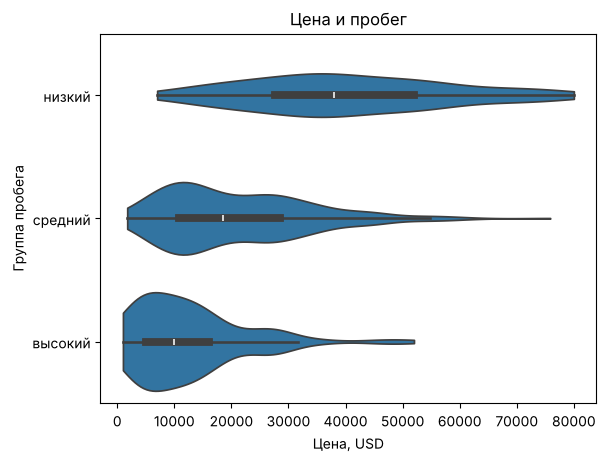

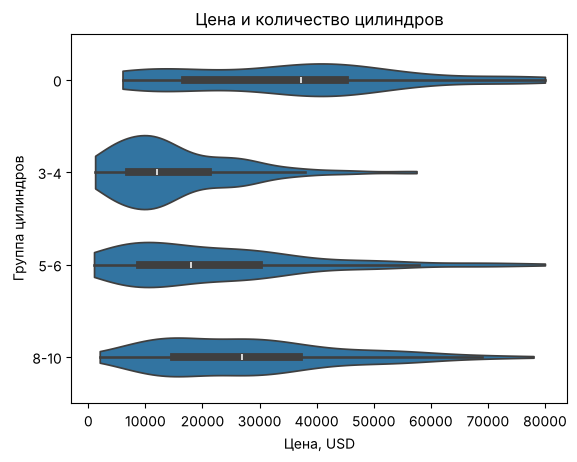

In [18]:
groups = ['низкий', 'средний', 'высокий']

sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Группа возраста', order=groups)
plt.title('Цена и возраст автомобиля')
plt.show()

sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Группа пробега', order=groups)
plt.title('Цена и пробег')
plt.show()

sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Группа цилиндров', order=['0', '3-4', '5-6', '8-10'])
plt.title('Цена и количество цилиндров')
plt.show()

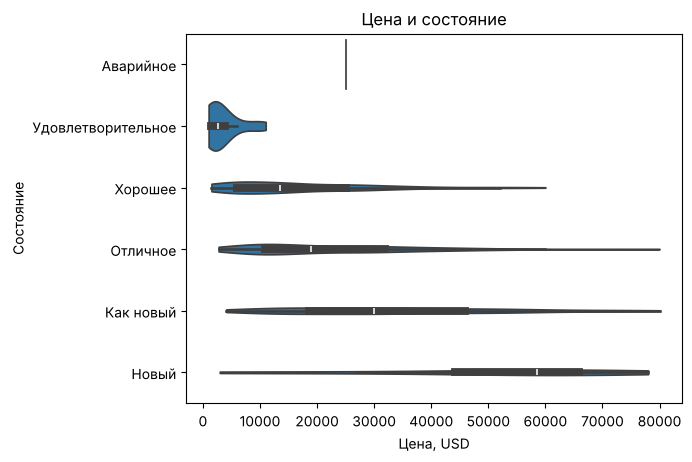

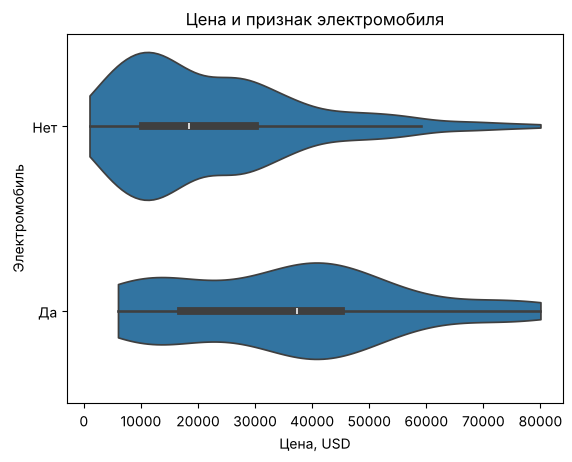

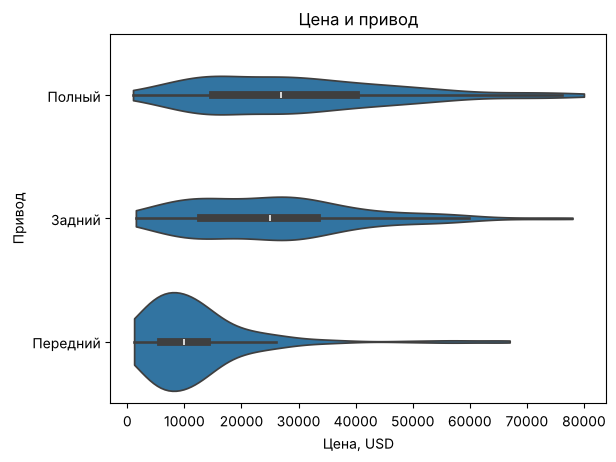

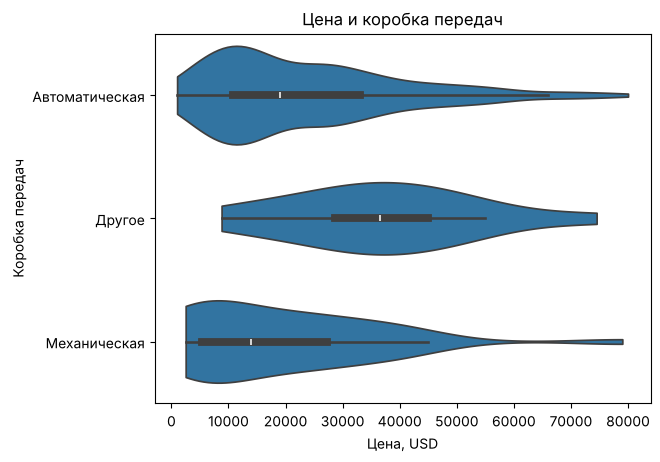

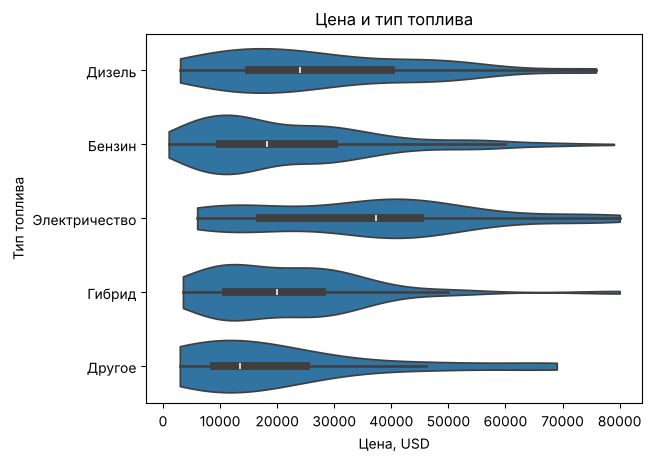

In [19]:
sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Состояние',
               order=['Аварийное', 'Удовлетворительное', 'Хорошее', 'Отличное', 'Как новый', 'Новый'])
plt.title('Цена и состояние')
plt.show()

sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Электромобиль')
plt.title('Цена и признак электромобиля')
plt.show()

sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Привод')
plt.title('Цена и привод')
plt.show()

sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Коробка передач')
plt.title('Цена и коробка передач')
plt.show()

sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Тип топлива')
plt.title('Цена и тип топлива')
plt.show()

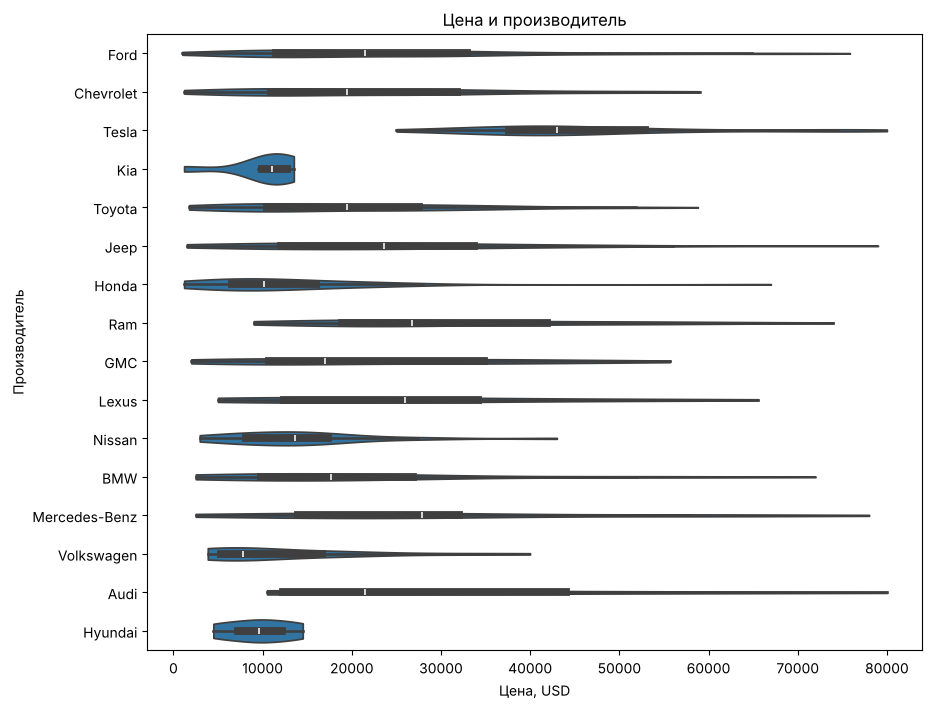

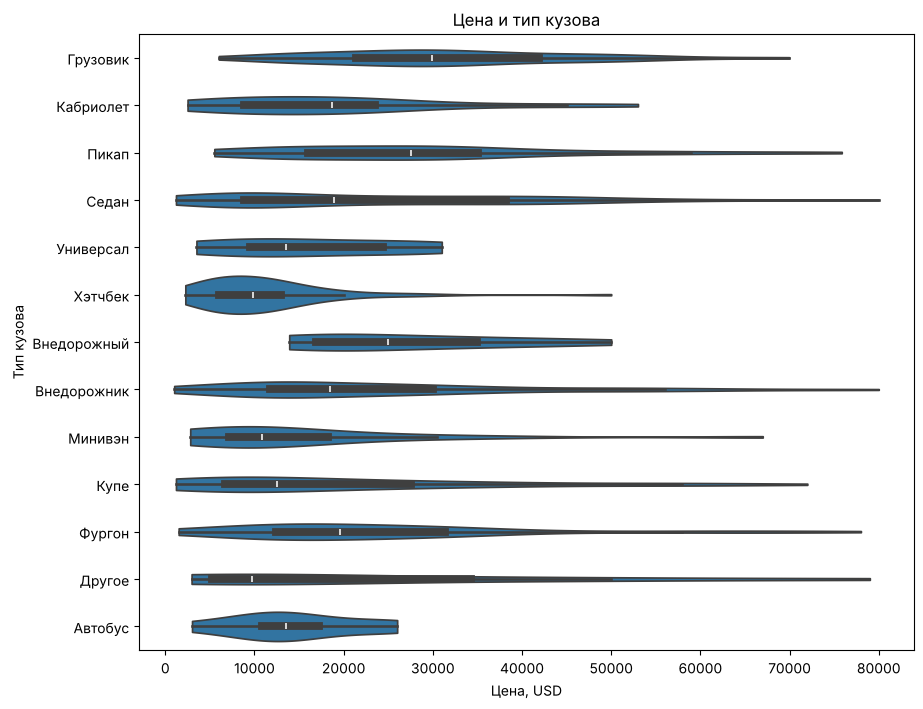

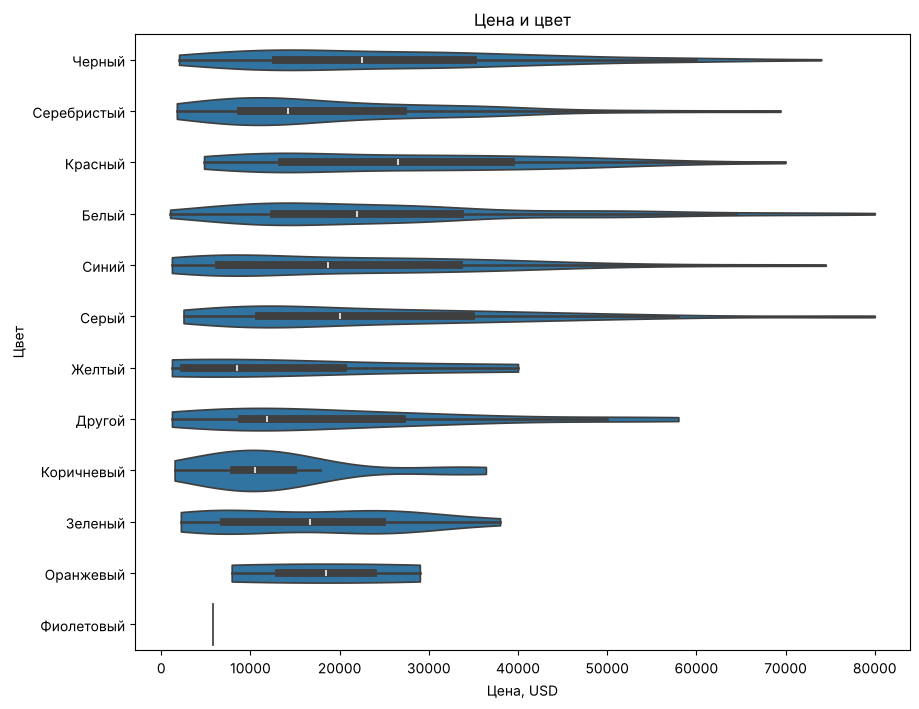

In [20]:
plt.figure(figsize=(10, 8))
sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Производитель')
plt.title('Цена и производитель')
plt.show()

plt.figure(figsize=(10, 8))
sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Тип кузова')
plt.title('Цена и тип кузова')
plt.show()

plt.figure(figsize=(10, 8))
sns.violinplot(data=df_viol, x='Цена, USD', cut=0, y='Цвет')
plt.title('Цена и цвет')
plt.show()

In [21]:
viol_cols = ['Группа возраста', 'Группа пробега', 'Группа цилиндров', 'Состояние', 'Электромобиль',
             'Привод', 'Коробка передач', 'Тип топлива', 'Производитель', 'Тип кузова', 'Цвет']

for col in viol_cols:
    print(df_viol.groupby(col)['Цена, USD'].agg(['count', 'median']).sort_values('median', ascending=False), '\n')

                 count   median
Группа возраста                
низкий             184  35956.0
средний            312  17750.0
высокий            155   8995.0 

                count   median
Группа пробега                
низкий            163  38000.0
средний           325  18500.0
высокий           163  10000.0 

                  count   median
Группа цилиндров                
0                    66  37281.5
8-10                210  26990.0
5-6                 218  17947.5
3-4                 157  11988.0 

                    count   median
Состояние                         
Новый                   8  58491.0
Как новый             138  29939.0
Аварийное               1  25000.0
Отличное              350  18994.5
Хорошее               140  13500.0
Удовлетворительное     14   2600.0 

               count   median
Электромобиль                
Да                66  37281.5
Нет              585  18500.0 

          count   median
Привод                  
Полный      314  26999.5
За

**Выводы по скрипичным графикам:**

- **Возраст.** Самая заметная связь с ценой. У новых машин (до 4 лет) медиана 35 956 USD, у машин от 4 до 11 лет - 17 750, у машин старше 11 лет - 8 995. Скрипка старых машин узкая и прижата к левому краю, у новых распределение широкое и сдвинуто вправо.
- **Пробег.** Картина похожая: при пробеге до 42 000 миль медиана 38 000 USD, при среднем пробеге 18 500, при пробеге выше 129 346 миль - 10 000. Чем больше пробег, тем ниже и компактнее распределение цен.
- **Количество цилиндров.** Связь немонотонная: самые дорогие электромобили с нулём цилиндров (медиана 37 281.5), затем машины с 8-10 цилиндрами (26 990), 5-6 цилиндрами (17 947.5) и 3-4 цилиндрами (11 988). Если не считать электромобили, цена растёт вместе с числом цилиндров.
- **Состояние.** Медиана растёт вместе с улучшением состояния: «Удовлетворительное» 2 600, «Хорошее» 13 500, «Отличное» 18 994.5, «Как новый» 29 939, «Новый» 58 491. Это подтверждает порядковую природу признака. Категория «Аварийное» представлена одной машиной (25 000), поэтому её скрипка вырождается в линию и по ней нельзя делать выводы.
- **Электромобиль.** Распределение цен электромобилей сдвинуто вправо: медиана 37 281.5 против 18 500 у остальных машин, то есть примерно вдвое выше.
- **Привод.** Медиана у полного привода 26 999.5, у заднего 25 000, у переднего 9 996. Скрипка переднего привода узкая и прижата к левому краю: это массовые недорогие легковые машины.
- **Коробка передач.** У категории «Другое» медиана 36 575, но в ней всего 15 машин (в основном электромобили). Автоматы (18 999) дороже механики (14 000), однако механических коробок всего 35.
- **Тип топлива.** Электромобили дороже всех (37 281.5), дальше дизель (24 000), гибрид (19 995), бензин (18 247.5) и «Другое» (13 500).
- **Производитель.** Самые высокие медианы у Tesla (42 997.5), Mercedes-Benz (27 900) и Ram (26 747.5), самые низкие у Hyundai (9 599.5) и Volkswagen (7 800). Часть марок представлена 8-10 машинами, поэтому их скрипки менее надёжны.
- **Тип кузова.** Дороже всего грузовики (29 938.5) и пикапы (27 500), дешевле всего хэтчбеки (9 800) и минивэны (10 900).
- **Цвет.** Медианы у распространённых цветов близки (белый 21 897.5, чёрный 22 500, серый 20 000), явной связи цвета с ценой не видно. Большие различия есть только у редких цветов, где всего от 1 до 4 машин.
- **Модель** скрипичным графиком не показана: 444 категории по 1-16 машин в каждой, распределение внутри таких групп построить нельзя.
- Общий вывод: сильнее всего с ценой связаны возраст, пробег, состояние, привод и признак электромобиля. Они будут кандидатами в предикторы регрессии.

## 6. Описательные статистики

### 6.1. Целевой признак: Цена, USD

In [22]:
price = df_final['Цена, USD']
price.describe().round(2)

count      651.00
mean     23767.13
std      16952.08
min       1000.00
25%      10500.00
50%      19500.00
75%      33500.00
max      80000.00
Name: Цена, USD, dtype: float64

In [23]:
print('Мода:', price.mode()[0])
print('Размах:', price.max() - price.min())
print('Интерквартильный размах (IQR):', price.quantile(0.75) - price.quantile(0.25))
print('Дисперсия:', round(price.var(), 2))
print('Коэффициент вариации, %:', round(price.std() / price.mean() * 100, 2))
print('Коэффициент асимметрии:', round(price.skew(), 2))
print('Доля машин дороже среднего, %:', round((price > price.mean()).mean() * 100, 2))

Мода: 11500
Размах: 79000
Интерквартильный размах (IQR): 23000.0
Дисперсия: 287372948.47
Коэффициент вариации, %: 71.33
Коэффициент асимметрии: 1.02
Доля машин дороже среднего, %: 44.24


**Интерпретация описательных статистик целевого признака:**

- **Медиана** равна 19 500 USD: половина автомобилей стоит дешевле этой суммы, половина дороже. Медиана устойчива к выбросам, поэтому лучше всего описывает типичную цену.
- **Среднее** равно 23 767.13 USD, оно на 4 267 USD больше медианы. Вместе с коэффициентом асимметрии 1.02 это говорит о правосторонней скошенности: дорогие машины тянут среднее вверх. Дороже среднего стоят только 44.24% автомобилей.
- **Мода** равна 11 500 USD - это самая частая цена в объявлениях. Для непрерывного признака мода малоинформативна.
- **Минимум и максимум:** от 1 000 до 80 000 USD, **размах** 79 000 USD. Это диапазон всех цен после удаления выбросов.
- **Квартили:** Q1 = 10 500 и Q3 = 33 500 USD. В этом интервале лежат центральные 50% цен, **межквартильный размах** равен 23 000 USD.
- **Стандартное отклонение** равно 16 952.08 USD: в среднем цена отклоняется от средней примерно на эту сумму. **Коэффициент вариации** 71.33% очень высокий, выборка охватывает и бюджетные, и дорогие автомобили.
- **Дисперсия** равна 287 372 948.47. Это квадрат стандартного отклонения, она измеряется в квадратах долларов и содержательно не интерпретируется.
- Вывод для моделирования: цены сильно различаются, значит, регрессии есть что объяснять. Скошенность распределения может ограничить качество линейной модели.

### 6.2. Предикторы

In [24]:
df_final[['Возраст автомобиля, лет', 'Пробег, миль', 'Количество цилиндров']].describe().round(2)

,"Возраст автомобиля, лет","Пробег, миль",Количество цилиндров
count,651.00,651.00,651.00
mean,8.24,89815.98,5.59
std,5.70,58968.60,2.46
min,0.00,10.00,0.00
25%,4.00,42000.00,4.00
50%,7.00,80384.00,6.00
75%,11.00,129345.50,8.00
max,31.00,260000.00,10.00


In [25]:
df_final.describe(include=object)

,Производитель,Модель,Состояние,Тип кузова,Тип топлива,Электромобиль,Коробка передач,Привод,Цвет
count,651,651,651,651,651,651,651,651,651
unique,16,444,6,13,5,2,3,3,12
top,Ford,f-150,Отличное,Внедорожник,Бензин,Нет,Автоматическая,Полный,Белый
freq,153,16,350,121,464,585,601,314,210


**Интерпретация описательных статистик предикторов:**

Для количественных признаков считаем среднее, медиану, квартили, стандартное отклонение, минимум и максимум:

- **Пробег, миль.** Медиана 80 384 мили, центральные 50% машин имеют пробег от 42 000 до 129 345.5 миль. Стандартное отклонение 58 968.60 миль сопоставимо с медианой: в выборке есть и почти новые машины (минимум 10 миль), и сильно подержанные (максимум 260 000). Среднее (89 815.98) больше медианы из-за правой асимметрии.
- **Возраст автомобиля, лет.** Медиана 7 лет, половина машин имеет возраст от 4 до 11 лет. Среднее 8.24 больше медианы, старые машины образуют правый хвост до 31 года. Стандартное отклонение 5.70 года.
- **Количество цилиндров.** Медиана 6, квартили 4 и 8 - это самые распространённые двигатели. Минимум 0 относится к электромобилям. Среднее 5.59 дробное и физически не существует, поэтому для дискретного признака медиана информативнее.

Для категориальных признаков считаем моду (top), её частоту (freq) и количество уникальных значений (unique):

- **Производитель:** 16 марок, мода - Ford (153 машины, 23.5%).
- **Модель:** 444 значения, мода - f-150 (16 машин). Это наибольшая вариативность в данных, поэтому признак не используется в модели.
- **Состояние:** 6 категорий, мода - «Отличное» (350, 53.8%).
- **Тип кузова:** 13 значений, мода - «Внедорожник» (121, 18.6%).
- **Тип топлива:** 5 значений, мода - «Бензин» (464, 71.3%).
- **Электромобиль:** 2 значения, мода - «Нет» (585, 89.9%), то есть доля электромобилей 10.1%.
- **Коробка передач:** 3 значения, мода - «Автоматическая» (601, 92.3%). Вариативность минимальная, выборка почти однородна по этому признаку.
- **Привод:** 3 значения, мода - «Полный» (314, 48.2%).
- **Цвет:** 12 значений, мода - «Белый» (210, 32.3%).

Для категориальных признаков среднее, медиана и стандартное отклонение не считаются: их значения - текстовые метки, арифметика над ними не определена.

## 7. Перекодирование данных

Регрессия и корреляция работают только с числами, поэтому категориальные признаки переводим в числовой вид. Способ кодирования зависит от типа признака. Работаем с очищенным датафреймом `df_final`.

### 7.1. One-Hot кодирование

In [26]:
df_encoded = pd.get_dummies(df_final, columns=['Электромобиль', 'Привод'], dtype=int)
df_encoded[['Электромобиль_Да', 'Электромобиль_Нет', 'Привод_Задний', 'Привод_Передний', 'Привод_Полный']].head()

,Электромобиль_Да,Электромобиль_Нет,Привод_Задний,Привод_Передний,Привод_Полный
0,0,1,0,0,1
1,0,1,0,0,1
2,0,1,1,0,0
3,0,1,0,0,1
4,1,0,1,0,0


### 7.2. LabelEncoder

In [27]:
df_encoded['Коробка_encoded'] = LabelEncoder().fit_transform(df_encoded['Коробка передач'])
df_encoded['Топливо_encoded'] = LabelEncoder().fit_transform(df_encoded['Тип топлива'])

print(df_encoded[['Коробка передач', 'Коробка_encoded']].drop_duplicates().sort_values('Коробка_encoded'), '\n')
print(df_encoded[['Тип топлива', 'Топливо_encoded']].drop_duplicates().sort_values('Топливо_encoded'))

   Коробка передач  Коробка_encoded
0   Автоматическая                0
4           Другое                1
29    Механическая                2 

      Тип топлива  Топливо_encoded
1          Бензин                0
6          Гибрид                1
0          Дизель                2
34         Другое                3
4   Электричество                4


### 7.3. OrdinalEncoder

In [28]:
order = [['Аварийное', 'Удовлетворительное', 'Хорошее', 'Отличное', 'Как новый', 'Новый']]
df_encoded['Состояние_encoded'] = OrdinalEncoder(categories=order).fit_transform(df_encoded[['Состояние']])

df_encoded[['Состояние', 'Состояние_encoded']].drop_duplicates().sort_values('Состояние_encoded')

,Состояние,Состояние_encoded
698,Аварийное,0.0
15,Удовлетворительное,1.0
1,Хорошее,2.0
0,Отличное,3.0
3,Как новый,4.0
115,Новый,5.0


**Выводы по перекодированию:**

- **One-Hot кодирование** применено к бинарному признаку `Электромобиль`: получены столбцы `Электромобиль_Да` и `Электромобиль_Нет` со значениями 1 и 0. Параметр `dtype=int` нужен, чтобы получить 1 и 0, а не True и False. В модели используется только `Электромобиль_Да`, потому что второй столбец полностью определяется первым (ловушка фиктивных переменных).
- Тем же способом закодирован номинальный признак `Привод`: столбцы `Привод_Задний`, `Привод_Передний`, `Привод_Полный`. В регрессию войдут два последних, а задний привод будет базовой категорией, с которой они сравниваются. LabelEncoder для привода не подходит: коды по алфавиту (Задний = 0, Передний = 1, Полный = 2) не совпадают с порядком цен (медианы 25 000, 9 996 и 26 999.5), и коэффициент при таком признаке нельзя было бы интерпретировать.
- **LabelEncoder** применён к номинальным признакам `Коробка передач` (Автоматическая = 0, Другое = 1, Механическая = 2) и `Тип топлива` (Бензин = 0, Гибрид = 1, Дизель = 2, Другое = 3, Электричество = 4). Коды присваиваются по алфавиту и не означают никакого порядка, поэтому эти столбцы не используются в корреляционной матрице и регрессии.
- **OrdinalEncoder** применён к порядковому признаку `Состояние` с явно заданным порядком: Аварийное = 0, Удовлетворительное = 1, Хорошее = 2, Отличное = 3, Как новый = 4, Новый = 5. Здесь числа отражают реальное улучшение состояния, что подтверждается ростом медианной цены на скрипичном графике.
- `Производитель` (16 категорий) и `Модель` (444 категории) не кодировались: номера по алфавиту создали бы ложную шкалу, а One-Hot для модели дал бы 444 столбца при 651 наблюдении.
- Результат сохранён в датафрейм **df_encoded**.

## 8. Корреляционный анализ

### 8.1. Парная корреляция: цена и пробег

In [29]:
print('Корреляция Пирсона:', round(df_encoded['Цена, USD'].corr(df_encoded['Пробег, миль']), 3))
print('Корреляция Спирмена:', round(df_encoded['Цена, USD'].corr(df_encoded['Пробег, миль'], method='spearman'), 3))

Корреляция Пирсона: -0.599
Корреляция Спирмена: -0.642


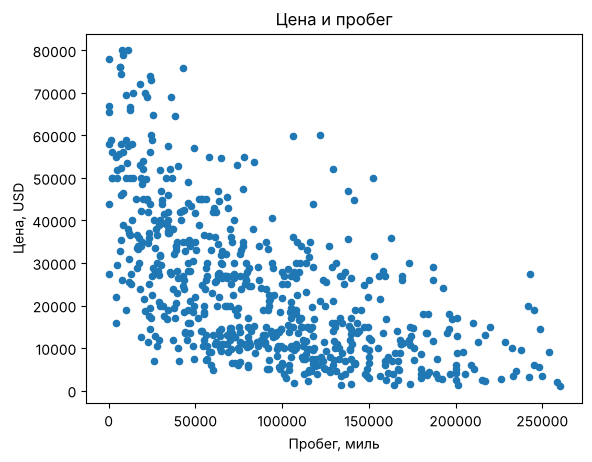

In [30]:
df_encoded.plot('Пробег, миль', 'Цена, USD', kind='scatter', title='Цена и пробег')
plt.show()

**Интерпретация коэффициента корреляции между ценой и пробегом:**

- Оба признака количественные, поэтому можно использовать корреляцию Пирсона.
- Коэффициент Пирсона равен -0.599: между ценой и пробегом существует **умеренная, близкая к сильной, обратная линейная связь**. Чем больше пробег автомобиля, тем ниже его цена.
- Коэффициент Спирмена равен -0.642, по модулю он больше коэффициента Пирсона. Значит, монотонная связь выражена сильнее линейной и связь скорее нелинейная. На диаграмме рассеяния облако точек изогнуто: при малом пробеге цена падает быстрее, чем при большом.
- Корреляция не говорит о причинно-следственной связи. Мы не можем утверждать, что именно пробег является причиной низкой цены: пробег связан и с возрастом машины, который тоже связан с ценой.

### 8.2. Корреляционная матрица

In [31]:
corr_cols = ['Цена, USD', 'Пробег, миль', 'Возраст автомобиля, лет', 'Количество цилиндров',
             'Состояние_encoded', 'Электромобиль_Да', 'Привод_Задний', 'Привод_Передний', 'Привод_Полный']

cm = df_encoded[corr_cols].corr(method='spearman').round(2)
cm

,"Цена, USD","Пробег, миль","Возраст автомобиля, лет",Количество цилиндров,Состояние_encoded,Электромобиль_Да,Привод_Задний,Привод_Передний,Привод_Полный
"Цена, USD",1.00,-0.64,-0.69,0.16,0.39,0.20,0.09,-0.49,0.36
"Пробег, миль",-0.64,1.00,0.69,0.19,-0.47,-0.26,-0.07,0.09,-0.02
"Возраст автомобиля, лет",-0.69,0.69,1.00,0.15,-0.44,-0.18,0.09,0.13,-0.19
Количество цилиндров,0.16,0.19,0.15,1.00,-0.14,-0.54,0.27,-0.44,0.16
Состояние_encoded,0.39,-0.47,-0.44,-0.14,1.00,0.12,-0.07,-0.04,0.10
Электромобиль_Да,0.20,-0.26,-0.18,-0.54,0.12,1.00,0.01,0.02,-0.03
Привод_Задний,0.09,-0.07,0.09,0.27,-0.07,0.01,1.00,-0.35,-0.54
Привод_Передний,-0.49,0.09,0.13,-0.44,-0.04,0.02,-0.35,1.00,-0.60
Привод_Полный,0.36,-0.02,-0.19,0.16,0.10,-0.03,-0.54,-0.60,1.00


In [32]:
cm[['Цена, USD']]

,"Цена, USD"
"Цена, USD",1.00
"Пробег, миль",-0.64
"Возраст автомобиля, лет",-0.69
Количество цилиндров,0.16
Состояние_encoded,0.39
Электромобиль_Да,0.20
Привод_Задний,0.09
Привод_Передний,-0.49
Привод_Полный,0.36


**Выбор коэффициента.** Корреляция Пирсона интерпретируется только между количественными признаками, а в матрице есть категориальные: порядковое `Состояние_encoded` и бинарные индикаторы электромобиля и привода. Поэтому строим матрицу Спирмена, она измеряет монотонную связь и устойчива к выбросам. Номинальные признаки с кодами LabelEncoder (`Коробка_encoded`, `Топливо_encoded`) в матрицу не включены: их коды не имеют порядка, и коэффициент для них не интерпретируется.

### 8.3. Топ-5 признаков по силе связи с ценой

In [33]:
cm['Цена, USD'].sort_values(key=abs, ascending=False).head(6)

Цена, USD                  1.00
Возраст автомобиля, лет   -0.69
Пробег, миль              -0.64
Привод_Передний           -0.49
Состояние_encoded          0.39
Привод_Полный              0.36
Name: Цена, USD, dtype: float64

**Выводы по корреляционному анализу:**

Сортируем коэффициенты по модулю (`key=abs`), потому что сила связи не зависит от знака. Первая строка - сама цена (корреляция признака с самим собой равна 1), дальше идут пять признаков с самой сильной связью:

1. **Возраст автомобиля, лет:** -0.69, умеренная, близкая к сильной, обратная монотонная связь. Чем старше автомобиль, тем ниже цена.
2. **Пробег, миль:** -0.64, умеренная, близкая к сильной, обратная монотонная связь.
3. **Привод_Передний:** -0.49, умеренная обратная связь. Передний привод может понижать стоимость автомобиля.
4. **Состояние_encoded:** 0.39, умеренная прямая монотонная связь. Чем лучше состояние, тем выше цена.
5. **Привод_Полный:** 0.36, умеренная прямая связь. Полный привод может повышать стоимость автомобиля.

Следом идут `Электромобиль_Да` (0.20, слабая прямая связь), `Количество цилиндров` (0.16, слабая) и `Привод_Задний` (0.09, связь практически отсутствует).

**Связи между предикторами.** Пробег и возраст связаны между собой (0.69): старые машины обычно больше проехали. Количество цилиндров связано с признаком электромобиля (-0.54), так как у электромобилей ноль цилиндров. Индикаторы переднего и полного привода связаны отрицательно (-0.60): машина не может иметь оба типа привода одновременно. Это нужно учитывать при выборе предикторов, чтобы избежать мультиколлинеарности.

## 9. Масштабирование данных

In [34]:
quant_cols = ['Пробег, миль', 'Возраст автомобиля, лет', 'Количество цилиндров']

df_scaled = df_encoded.copy()
df_scaled[quant_cols] = StandardScaler().fit_transform(df_scaled[quant_cols])

print('Средние после масштабирования:')
print(df_scaled[quant_cols].mean().round(3), '\n')
print('Стандартные отклонения после масштабирования:')
print(df_scaled[quant_cols].std().round(3))

Средние после масштабирования:
Пробег, миль               0.0
Возраст автомобиля, лет   -0.0
Количество цилиндров       0.0
dtype: float64 

Стандартные отклонения после масштабирования:
Пробег, миль               1.001
Возраст автомобиля, лет    1.001
Количество цилиндров       1.001
dtype: float64


**Выводы по масштабированию:**

- Количественные предикторы (`Пробег, миль`, `Возраст автомобиля, лет`, `Количество цилиндров`) нормализованы с помощью `StandardScaler`. Из каждого значения вычитается среднее признака, и результат делится на стандартное отклонение. После преобразования среднее каждого признака равно 0 (значение -0.0 - это ноль с погрешностью округления), а стандартное отклонение примерно 1 (1.001, потому что `StandardScaler` делит на n, а `std()` в pandas на n - 1).
- Зачем это нужно: пробег измеряется десятками тысяч миль, а возраст единицами лет. После нормализации оба признака измеряются в стандартных отклонениях, и их коэффициенты в регрессии можно сравнивать между собой.
- Целевая переменная `Цена, USD` не масштабируется, чтобы коэффициенты и ошибки модели читались в долларах. Закодированные категориальные признаки тоже не масштабируются: это метки 0/1 и номера категорий, а не измеренные величины.
- Результат сохранён в датафрейм **df_scaled**, регрессия строится на нём.

## 10. Линейная регрессия

### 10.1. Описание модели

Мы хотим построить модель, которая предсказывает цену подержанного автомобиля в долларах на основании его пробега, возраста, технического состояния, типа привода и того, является ли он электромобилем.

Отбор предикторов:

- В модель входят все пять признаков из топ-5 по корреляции с ценой: `Возраст автомобиля, лет`, `Пробег, миль` (нормализованные), `Привод_Передний`, `Состояние_encoded`, `Привод_Полный`, и следующий за ними `Электромобиль_Да`.
- `Привод_Задний` не включаем: это базовая категория привода. Если включить все три индикатора, они дублируют друг друга (ловушка фиктивных переменных).
- `Количество цилиндров` не включаем: связь с ценой слабая (0.16), а с признаком электромобиля заметная (-0.54).
- Пробег и возраст связаны между собой (0.69), но связь ниже порога сильной (0.7), и оба признака сильно связаны с ценой, поэтому оставляем оба.
- В модели 6 предикторов при 651 наблюдении, то есть около 108 наблюдений на предиктор. Требование «минимум 100 наблюдений на предиктор» выполнено.

Модель:

$$\text{Цена} = w_0 + w_1 \cdot \text{Пробег} + w_2 \cdot \text{Возраст} + w_3 \cdot \text{Состояние} + w_4 \cdot \text{Электромобиль} + w_5 \cdot \text{Передний} + w_6 \cdot \text{Полный}$$

где пробег и возраст нормализованы `StandardScaler`.

### 10.2. Деление выборки на тренировочную и тестовую

In [35]:
X = df_scaled[['Пробег, миль', 'Возраст автомобиля, лет', 'Состояние_encoded',
               'Электромобиль_Да', 'Привод_Передний', 'Привод_Полный']]
Y = df_scaled['Цена, USD']

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print('Тренировочная выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

Тренировочная выборка: (520, 6)
Тестовая выборка: (131, 6)


Масштабированные данные разделены в соотношении 80 на 20: 520 автомобилей для обучения и 131 для проверки качества. Тренировочная выборка нужна, чтобы найти коэффициенты методом наименьших квадратов, тестовая - чтобы честно оценить качество на машинах, которых модель не видела. `random_state=42` фиксирует случайное разбиение, чтобы результат повторялся при каждом запуске.

### 10.3. Обучение модели и уравнение

In [36]:
model = LinearRegression().fit(X_train, y_train)
print(model.intercept_)

19722.850462697676


In [37]:
model.coef_

array([ -5755.63752165,  -5118.15310861,   1958.14509302,   5368.1648777 ,
       -12290.68913446,   2031.34140164])

Коэффициенты в `model.coef_` идут в порядке столбцов X: пробег, возраст, состояние, электромобиль, передний привод, полный привод.

**Уравнение обученной модели:**

$$\text{Цена} = 19722.85 - 5755.64 \cdot \text{Пробег} - 5118.15 \cdot \text{Возраст} + 1958.15 \cdot \text{Состояние} + 5368.16 \cdot \text{Электромобиль} - 12290.69 \cdot \text{Передний} + 2031.34 \cdot \text{Полный}$$

### 10.4. Интерпретация параметров модели

- **$w_0 = 19\,722.85$.** Если все предикторы равны нулю, цена равна 19 722.85 USD. Ноль у нормализованного признака означает среднее значение, поэтому это автомобиль со средним пробегом и средним возрастом, в аварийном состоянии (код 0), не электромобиль, с задним приводом. Такое сочетание в данных почти не встречается, поэтому свободный коэффициент служит точкой отсчёта и содержательно не интерпретируется.
- **$w_1 = -5\,755.64$.** Если пробег вырастет на одно стандартное отклонение (58 968.60 миль), цена снизится в среднем на 5 755.64 USD при прочих равных. В пересчёте это примерно 98 USD на каждую тысячу миль.
- **$w_2 = -5\,118.15$.** Если возраст вырастет на одно стандартное отклонение (5.70 года), цена снизится в среднем на 5 118.15 USD при прочих равных, то есть примерно на 899 USD за каждый год.
- **$w_3 = 1\,958.15$.** Если состояние улучшится на одну ступень (например, с «Хорошего» до «Отличного»), цена вырастет в среднем на 1 958.15 USD при прочих равных.
- **$w_4 = 5\,368.16$.** Если автомобиль является электромобилем (признак равен 1), его цена в среднем на 5 368.16 USD выше, чем у машины с обычным двигателем, при прочих равных.
- **$w_5 = -12\,290.69$.** Если у автомобиля передний привод (признак равен 1), его цена в среднем на 12 290.69 USD ниже, чем у машины с задним приводом, при прочих равных.
- **$w_6 = 2\,031.34$.** Если у автомобиля полный привод (признак равен 1), его цена в среднем на 2 031.34 USD выше, чем у машины с задним приводом, при прочих равных.
- Пробег и возраст нормализованы, поэтому их коэффициенты можно сравнивать: вклад пробега (-5 755.64) немного больше вклада возраста (-5 118.15). Самый большой по модулю коэффициент у переднего привода: переднеприводные машины - массовый недорогой сегмент.

### 10.5. Метрики качества модели

In [38]:
y_pred = model.predict(X_test)

print('R2 =', round(r2_score(y_test, y_pred), 3))
print('MSE =', round(mean_squared_error(y_test, y_pred), 2))
print('MAE =', round(mean_absolute_error(y_test, y_pred), 2))
print('Средняя цена в тестовой выборке:', round(y_test.mean(), 2))

R2 = 0.613
MSE = 103084860.6
MAE = 8110.01
Средняя цена в тестовой выборке: 24596.49


**Интерпретация метрик качества обученной модели:**

- **$R^2 = 0.613$.** Модель объясняет 61.3% разброса цен автомобилей в тестовой выборке, а 38.7% вариации остались не описаны моделью. Метрика принимает значения от 0 до 1, чем ближе к 1, тем лучше. Значение 0.613 означает, что модель заметно лучше простой подстановки средней цены, но далека от точной.
- **$MAE = 8\,110.01$.** В среднем модель ошибается на 8 110.01 USD. При средней цене в тестовой выборке 24 596.49 USD это около 33%, поэтому для точной оценки стоимости конкретной машины модель не подходит. MAE измеряется в долларах и читается содержательно.
- **$MSE = 103\,084\,860.6$.** Это средний квадрат ошибки, он измеряется в квадратах долларов, поэтому его абсолютное значение не интерпретируется. MSE используется для сравнения моделей с одной и той же целевой переменной: чем меньше, тем лучше.
- **Общий вывод.** Все коэффициенты имеют ожидаемые знаки: цена ниже при большем пробеге и возрасте, выше при лучшем состоянии, у электромобилей и полноприводных машин, ниже у переднеприводных. Точность модели ограничена, потому что в неё не вошли марка, модель и комплектация автомобиля.

## 11. Тестирование гипотез

Проведены все изученные тесты: тест Шапиро-Уилка и семь статистических тестов. Для каждого теста приводятся словесная формулировка, проверка предпосылок, гипотезы $H_0$ и $H_1$ и вывод. Вывод делается по p-value на трёх уровнях значимости: 1%, 5% и 10%. Если p-value меньше уровня значимости, $H_0$ отвергается, если больше - не отвергается. Все тесты проводятся на очищенных данных `df_final`.

### 11.1. Тест Шапиро-Уилка

**Словесная формулировка.** Мы хотим проверить, распределены ли нормально цена, пробег и возраст автомобиля. От результата зависит выбор следующих тестов: z-тест и t-тесты предполагают нормальное распределение признака, тест Манна-Уитни этого не требует. Дополнительно проверяем логарифм цены.

$H_0: X \sim N(\mu, \sigma^2)$ - признак распределён нормально

$H_1: X \nsim N(\mu, \sigma^2)$ - признак распределён не нормально

In [39]:
res = shapiro(df_final['Цена, USD'])
print('Цена, USD: W =', round(res[0], 4), ', p-value =', res[1])

res = shapiro(df_final['Пробег, миль'])
print('Пробег, миль: W =', round(res[0], 4), ', p-value =', res[1])

res = shapiro(df_final['Возраст автомобиля, лет'])
print('Возраст автомобиля, лет: W =', round(res[0], 4), ', p-value =', res[1])

res = shapiro(np.log(df_final['Цена, USD']))
print('ln(Цена, USD): W =', round(res[0], 4), ', p-value =', res[1])

Цена, USD: W = 0.9148 , p-value = 1.159062202201416e-18
Пробег, миль: W = 0.9585 , p-value = 1.352414904423235e-12
Возраст автомобиля, лет: W = 0.9023 , p-value = 5.698633992382696e-20
ln(Цена, USD): W = 0.9717 , p-value = 6.74272597040754e-10


**Интерпретация.**

- Для всех четырёх признаков p-value намного меньше 0.01, поэтому $H_0$ отвергается на уровнях 1%, 5% и 10%: ни цена, ни пробег, ни возраст не распределены нормально. Это согласуется с гистограммами, где у всех трёх признаков длинный правый хвост.
- После логарифмирования цены статистика W выросла с 0.9148 до 0.9717, распределение стало ближе к нормальному, но нормальность всё равно отвергается.
- Следствие: строго говоря, предпосылка нормальности для z-теста и t-тестов нарушена. Выборка большая (651 автомобиль, в сравниваемых группах не меньше 35), поэтому среднее выборки распределено приблизительно нормально, и в z-тесте и t-тестах мы, как в кейсах лекции, **будем считать признак нормально распределённым**. Для сравнения групп без этого допущения используется тест Манна-Уитни.

### 11.2. Z-тест

**Словесная формулировка.** Мы хотим проверить гипотезу о том, что средняя цена подержанного автомобиля равна 25 000 USD, если считать, что цена распределена нормально, а дисперсия генеральной совокупности совпадает с выборочной.

**Предпосылки:** признак нормально распределён (принимаем как допущение, см. п. 11.1), дисперсия генеральной совокупности известна (считаем равной выборочной), наблюдений не менее 30 (у нас 651). Предпосылки выполнены.

$H_0: \mu_{цена} = 25000$

$H_1: \mu_{цена} \neq 25000$

In [40]:
z_stat, p_value = ztest(df_final['Цена, USD'], value=25000, alternative='two-sided')

print('Выборочное среднее:', round(df_final['Цена, USD'].mean(), 2))
print('z-статистика:', round(z_stat, 4))
print('p-value:', round(p_value, 4))

Выборочное среднее: 23767.13
z-статистика: -1.8556
p-value: 0.0635


**Интерпретация.** Выборочное среднее 23 767.13 USD, p-value = 0.0635.

- На уровне 1%: 0.0635 > 0.01, $H_0$ не отвергается.
- На уровне 5%: 0.0635 > 0.05, $H_0$ не отвергается.
- На уровне 10%: 0.0635 < 0.10, $H_0$ отвергается.

На уровнях 1% и 5% нет оснований считать, что средняя цена отличается от 25 000 USD. На уровне 10% отличие признаётся значимым, то есть результат пограничный.

### 11.3. Одновыборочный t-тест

**Словесная формулировка.** Мы хотим проверить гипотезу о том, что средняя цена подержанного автомобиля больше 22 000 USD, если считать, что цена распределена нормально. В отличие от z-теста дисперсия генеральной совокупности не считается известной.

**Предпосылки:** признак нормально распределён (принимаем как допущение, см. п. 11.1). Предпосылка выполнена.

$H_0: \mu_{цена} = 22000$

$H_1: \mu_{цена} > 22000$

In [41]:
stats.ttest_1samp(df_final['Цена, USD'], popmean=22000, alternative='greater')

TtestResult(statistic=np.float64(2.659721670828892), pvalue=np.float64(0.0040066568788041405), df=np.int64(650))

**Интерпретация.** p-value = 0.0040.

- На уровне 1%: 0.0040 < 0.01, $H_0$ отвергается.
- На уровне 5% и 10% $H_0$ тоже отвергается.

На всех уровнях значимости средняя цена подержанного автомобиля статистически значимо больше 22 000 USD.

### 11.4. Парный t-тест

**Словесная формулировка.** Парный t-тест сравнивает средние двух связанных выборок, то есть двух измерений на одних и тех же объектах. Например: мы хотели бы проверить, что средняя цена автомобиля до ремонта ниже, чем после ремонта.

**Предпосылки:** выборки связаны, разность выборок нормально распределена.

$H_0: \mu_{до} = \mu_{после}$, или $\mu_{до} - \mu_{после} = 0$

$H_1: \mu_{до} < \mu_{после}$

**Почему тест нельзя провести на наших данных.** Каждая строка датасета - отдельный автомобиль, измеренный один раз. В данных нет двух измерений одного и того же автомобиля (до и после, в разные моменты времени), поэтому связанных выборок нет и первая предпосылка теста не выполняется. Разбить выборку на две части и назвать их парными нельзя: парность требует, чтобы каждое наблюдение одной выборки относилось к тому же объекту, что и наблюдение другой. Поэтому парный t-тест не проводится.

### 11.5. Двухвыборочный t-тест

**Словесная формулировка.** Мы хотим проверить гипотезу о том, что средняя цена автомобилей с автоматической коробкой передач равна средней цене автомобилей с механической коробкой, если считать, что цены в обеих группах распределены нормально.

$H_0: \mu_{автомат} = \mu_{механика}$

$H_1: \mu_{автомат} \neq \mu_{механика}$

In [42]:
auto = df_final[df_final['Коробка передач'] == 'Автоматическая']['Цена, USD']
mech = df_final[df_final['Коробка передач'] == 'Механическая']['Цена, USD']

print('Автомат: количество =', auto.count(), ', среднее =', round(auto.mean(), 2), ', std =', round(auto.std(), 2))
print('Механика: количество =', mech.count(), ', среднее =', round(mech.mean(), 2), ', std =', round(mech.std(), 2))

Автомат: количество = 601 , среднее = 23695.92 , std = 16829.6
Механика: количество = 35 , среднее = 19328.43 , std = 16780.35


In [43]:
stats.ttest_ind(auto, mech, alternative='two-sided')

TtestResult(statistic=np.float64(1.4926875120502463), pvalue=np.float64(0.13601644353955847), df=np.float64(634.0))

**Предпосылки.** Выборки не связаны: каждый автомобиль относится только к одной группе. Нормальность принимаем как допущение (см. п. 11.1). Дисперсии можно считать равными: стандартные отклонения в группах почти совпадают (16 829.60 и 16 780.35 USD). Предпосылки выполнены.

**Интерпретация.** p-value = 0.1360.

- На уровнях 1%, 5% и 10% p-value больше уровня значимости, $H_0$ не отвергается.

Средняя цена автоматов (23 695.92 USD) выше, чем у механики (19 328.43 USD), но статистически эта разница не значима: в группе механики всего 35 машин, и такое расхождение может быть случайным. Утверждать, что средние цены этих групп различаются, нельзя.

### 11.6. Тест Манна-Уитни (U-тест)

**Словесная формулировка.** Мы хотим проверить, отличается ли уровень цен автомобилей с полным приводом от уровня цен автомобилей с задним приводом. Тест Манна-Уитни не требует нормального распределения, поэтому подходит для наших данных.

$H_0$: уровень цен автомобилей с полным приводом не отличается от уровня цен автомобилей с задним приводом

$H_1$: уровень цен автомобилей с полным приводом отличается от уровня цен автомобилей с задним приводом

In [44]:
full_drive = df_final[df_final['Привод'] == 'Полный']['Цена, USD']
rear_drive = df_final[df_final['Привод'] == 'Задний']['Цена, USD']
front_drive = df_final[df_final['Привод'] == 'Передний']['Цена, USD']

print('Асимметрия: полный =', round(full_drive.skew(), 2),
      ', задний =', round(rear_drive.skew(), 2),
      ', передний =', round(front_drive.skew(), 2))
print('Медиана: полный =', full_drive.median(), ', задний =', rear_drive.median())

Асимметрия: полный = 0.75 , задний = 0.77 , передний = 2.8
Медиана: полный = 26999.5 , задний = 25000.0


In [45]:
stats.mannwhitneyu(full_drive, rear_drive, alternative='two-sided')

MannwhitneyuResult(statistic=np.float64(28023.5), pvalue=np.float64(0.015392660349809541))

**Предпосылки.** Выборки не связаны: у каждого автомобиля один тип привода. Форма распределений одинаковая: оба распределения скошены вправо примерно одинаково (асимметрия 0.75 и 0.77) и имеют одну вершину (см. скрипичный график привода). Предпосылки выполнены. Пару «полный и передний привод» мы не берём: у переднего привода асимметрия 2.80, форма распределения другая.

**Интерпретация.** p-value = 0.0154.

- На уровне 1%: 0.0154 > 0.01, $H_0$ не отвергается.
- На уровне 5%: 0.0154 < 0.05, $H_0$ отвергается.
- На уровне 10%: 0.0154 < 0.10, $H_0$ отвергается.

На уровнях 5% и 10% цены автомобилей с полным приводом статистически значимо выше, чем с задним (медианы 26 999.5 и 25 000 USD). На строгом уровне 1% различие не подтверждается, потому что разница между группами небольшая.

### 11.7. Z-тест для пропорций

**Словесная формулировка.** Мы хотим проверить, отличается ли доля электромобилей среди дорогих и дешёвых автомобилей. Дорогими считаем машины дороже медианной цены (19 500 USD), остальные - дешёвыми.

**Предпосылки:** выборки не связаны (каждая машина попадает только в один сегмент), признак бинарный (`Электромобиль_Да` равен 0 или 1). Предпосылки выполнены.

$H_0: p_{дорогие} = p_{дешёвые}$

$H_1: p_{дорогие} \neq p_{дешёвые}$

In [46]:
df_prop = df_encoded.copy()
df_prop['Сегмент'] = np.where(df_prop['Цена, USD'] > df_prop['Цена, USD'].median(), 'дорогие', 'дешёвые')

gb = df_prop.groupby('Сегмент')['Электромобиль_Да'].agg(['sum', 'count'])
gb['доля, %'] = (gb['sum'] / gb['count'] * 100).round(1)
gb

,sum,count,"доля, %"
Сегмент,,,
дешёвые,19,328,5.8
дорогие,47,323,14.6


In [47]:
proportions_ztest(gb['sum'], gb['count'], alternative='two-sided')

(np.float64(-3.701720168524791), np.float64(0.00021414272110861622))

**Интерпретация.** p-value = 0.0002.

- На уровнях 1%, 5% и 10% p-value меньше уровня значимости, $H_0$ отвергается.

Доля электромобилей среди дорогих машин (14.6%, 47 из 323) статистически значимо выше, чем среди дешёвых (5.8%, 19 из 328). Это согласуется со скрипичным графиком: медианная цена электромобиля 37 281.5 USD, у остальных машин 18 500.

### 11.8. Хи-квадрат

**Словесная формулировка.** Мы хотим проверить, связан ли тип привода автомобиля с тем, является ли автомобиль электромобилем.

**Предпосылки:** признаки категориальные, в каждой группе таблицы сопряжённости не менее 5 наблюдений.

$H_0$: тип привода не связан с тем, является ли автомобиль электромобилем

$H_1$: тип привода связан с тем, является ли автомобиль электромобилем

In [48]:
check = df_final[['Привод', 'Тип топлива']].value_counts().unstack()
check

Тип топлива,Бензин,Гибрид,Дизель,Другое,Электричество
Привод,,,,,
Задний,115,3,11,11,17
Передний,124,25,4,7,20
Полный,225,21,32,7,29


Сначала мы рассматривали пару «Привод и Тип топлива», но в её таблице есть группы меньше 5 наблюдений (задний привод и гибрид - 3 машины, передний привод и дизель - 4), то есть предпосылка теста нарушена. Пара «Электромобиль и Привод» - единственная пара категориальных признаков в наших данных, где во всех группах не меньше 5 наблюдений, поэтому тест проводим для неё.

In [49]:
gb = df_final[['Электромобиль', 'Привод']].value_counts().unstack()
gb

Привод,Задний,Передний,Полный
Электромобиль,,,
Да,17,20,29
Нет,140,160,285


In [50]:
stats.chi2_contingency(gb.values)

Chi2ContingencyResult(statistic=np.float64(0.5497697042283034), pvalue=np.float64(0.7596595913848974), dof=2, expected_freq=array([[ 15.91705069,  18.24884793,  31.83410138],
       [141.08294931, 161.75115207, 282.16589862]]))

**Интерпретация.** В каждой группе таблицы не меньше 17 наблюдений, предпосылка выполнена. p-value = 0.7597.

- На уровнях 1%, 5% и 10% p-value больше уровня значимости, $H_0$ не отвергается.

Тип привода не связан с тем, является ли автомобиль электромобилем: доля электромобилей примерно одинакова при заднем (17 из 157, 10.8%), переднем (20 из 180, 11.1%) и полном приводе (29 из 314, 9.2%).

### 11.9. Сводная таблица результатов

| № | Тест | Что проверяли | p-value | Вывод при $\alpha = 0.05$ |
|---|---|---|---|---|
| 1 | Шапиро-Уилка | нормальность цены | $1.16 \cdot 10^{-18}$ | $H_0$ отвергается |
| 2 | Z-тест | средняя цена = 25 000 | 0.0635 | $H_0$ не отвергается |
| 3 | Одновыборочный t-тест | средняя цена > 22 000 | 0.0040 | $H_0$ отвергается |
| 4 | Парный t-тест | нет связанных выборок | - | тест неприменим |
| 5 | Двухвыборочный t-тест | автомат = механика | 0.1360 | $H_0$ не отвергается |
| 6 | Манна-Уитни | полный = задний привод | 0.0154 | $H_0$ отвергается |
| 7 | Z-тест для пропорций | доля электромобилей в сегментах | 0.0002 | $H_0$ отвергается |
| 8 | Хи-квадрат | привод и электромобиль не связаны | 0.7597 | $H_0$ не отвергается |

## 12. Общие выводы по проекту

- **Данные.** Исходные 700 объявлений очищены в три этапа: удалены 35 дубликатов и заполнены пропуски (665 строк), удалены 8 выбросов по цене методом трёх стандартных отклонений (657 строк) и 6 выбросов по пробегу методом 1.5 * IQR (651 строка). Всего потеряно 7% наблюдений.
- **Распределения.** Цена, пробег и возраст скошены вправо: медианная цена 19 500 USD при среднем 23 767, коэффициент вариации цены 71%. Категориальные признаки распределены неравномерно: 71% машин бензиновые, 92% с автоматической коробкой, 90% не электромобили.
- **Связи.** Сильнее всего с ценой связаны возраст (-0.69) и пробег (-0.64): чем старше машина и чем больше пробег, тем ниже цена. Далее идут передний привод (-0.49), состояние (0.39) и полный привод (0.36).
- **Модель.** Линейная регрессия на шести предикторах объясняет 61.3% разброса цен на тестовой выборке, в среднем ошибается на 8 110 USD (около 33% средней цены). Знаки всех коэффициентов соответствуют ожиданиям, но для точной оценки конкретной машины модели не хватает марки, модели и комплектации.
- **Гипотезы.** Средняя цена значимо больше 22 000 USD; цены полноприводных машин выше, чем заднеприводных (на уровне 5%); доля электромобилей среди дорогих машин выше. Не подтвердились различие средних цен автоматов и механики и связь привода с признаком электромобиля. Парный t-тест неприменим, так как в данных нет связанных выборок.